In [ ]:
import os
print(os.getcwd())
print(os.listdir())

/content
['.config', 'sample_data']


In [ ]:
import os, time, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, clear_output, HTML

raw = pd.read_csv("/content/water_potability.csv")
print(raw.shape)
raw.head()

(3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [ ]:
rng = np.random.default_rng(42)

df = raw[["ph", "Solids", "Turbidity", "Potability"]].copy()
df.columns = ["ph", "tds", "turbidity", "potable"]
df["ph"] = df["ph"].fillna(df["ph"].median()).clip(0, 14).round(2)
df["tds"] = (df["tds"] / 60).round(0)                     # scale to realistic ppm
df["turbidity"] = df["turbidity"].round(2)
df["temperature"] = rng.normal(27, 2, len(df)).round(1)   # simulated temperature
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

df[["ph", "tds", "turbidity", "temperature"]].describe().round(2)

,ph,tds,turbidity,temperature
count,3276.00,3276.00,3276.00,3276.00
mean,7.07,366.90,3.97,26.96
std,1.47,146.15,0.78,2.01
min,0.00,5.00,1.45,19.70
25%,6.28,261.00,3.44,25.60
50%,7.04,349.00,3.96,27.00
75%,7.87,456.00,4.50,28.30
max,14.00,1020.00,6.74,33.40


In [ ]:
DB = "water_monitor.db"
if os.path.exists(DB):
    os.remove(DB)
conn = sqlite3.connect(DB)
conn.execute("""
CREATE TABLE readings (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    ts TEXT, ph REAL, tds REAL, turbidity REAL, temperature REAL,
    status TEXT, alert_msg TEXT
)""")
conn.commit()
print("Database ready")

Database ready


In [ ]:
LIMITS = {
    "ph":          (6.5, 8.5),
    "tds":         (0, 500),     # ppm
    "turbidity":   (0, 5),       # NTU
    "temperature": (10, 35),     # deg C
}

def check_reading(r):
    problems = []
    for name, (lo, hi) in LIMITS.items():
        v = r[name]
        if v < lo:
            problems.append(f"{name} too low ({v})")
        elif v > hi:
            problems.append(f"{name} too high ({v})")
    if not problems:
        return "NORMAL", ""
    unsafe = len(problems) >= 2 or r["ph"] < 5.5 or r["ph"] > 9.5
    status = "UNSAFE" if unsafe else "ATTENTION REQUIRED"
    return status, "Abnormal Water Quality Detected: " + "; ".join(problems)

print(check_reading({"ph": 7.2, "tds": 350, "turbidity": 2, "temperature": 27}))
print(check_reading({"ph": 4.5, "tds": 350, "turbidity": 2, "temperature": 27}))

('NORMAL', '')
('UNSAFE', 'Abnormal Water Quality Detected: ph too low (4.5)')


In [ ]:
def send_reading(r, ts=None):
    ts = ts or pd.Timestamp.now().strftime("%Y-%m-%d %H:%M:%S")
    status, msg = check_reading(r)
    conn.execute(
        "INSERT INTO readings (ts, ph, tds, turbidity, temperature, status, alert_msg) VALUES (?,?,?,?,?,?,?)",
        (ts, r["ph"], r["tds"], r["turbidity"], r["temperature"], status, msg))
    conn.commit()
    return status, msg

N = 300
start = pd.Timestamp.now().floor("min") - pd.Timedelta(minutes=5 * N)
for i, row in df.head(N).iterrows():
    ts = (start + pd.Timedelta(minutes=5 * i)).strftime("%Y-%m-%d %H:%M:%S")
    send_reading(row[["ph", "tds", "turbidity", "temperature"]].to_dict(), ts)

pd.read_sql("SELECT * FROM readings ORDER BY id DESC LIMIT 5", conn)

,id,ts,ph,tds,turbidity,temperature,status,alert_msg
0,300,2026-09-24 10:04:00,8.16,457.0,3.67,29.9,NORMAL,
1,299,2026-09-24 09:59:00,6.94,282.0,4.24,27.9,NORMAL,
2,298,2026-09-24 09:54:00,9.02,331.0,3.99,27.7,ATTENTION REQUIRED,Abnormal Water Quality Detected: ph too high (...
3,297,2026-09-24 09:49:00,6.73,103.0,3.77,27.4,NORMAL,
4,296,2026-09-24 09:44:00,7.04,510.0,3.11,26.7,ATTENTION REQUIRED,Abnormal Water Quality Detected: tds too high ...


In [ ]:
hist = pd.read_sql("SELECT * FROM readings ORDER BY id", conn, parse_dates=["ts"])

print("Status counts:")
print(hist["status"].value_counts(), "\n")
print("Average / min / max per parameter:")
display(hist[["ph", "tds", "turbidity", "temperature"]].agg(["mean", "min", "max"]).round(2))

causes = {p: int(hist["alert_msg"].str.contains(p).sum()) for p in LIMITS}
print("Alerts caused by each parameter:", causes)

Status counts:
status
NORMAL                135
UNSAFE                 87
ATTENTION REQUIRED     78
Name: count, dtype: int64 

Average / min / max per parameter:


,ph,tds,turbidity,temperature
mean,7.06,361.06,3.95,26.92
min,1.84,5.00,1.45,21.30
max,13.18,922.00,6.36,32.80


Alerts caused by each parameter: {'ph': 132, 'tds': 49, 'turbidity': 30, 'temperature': 0}


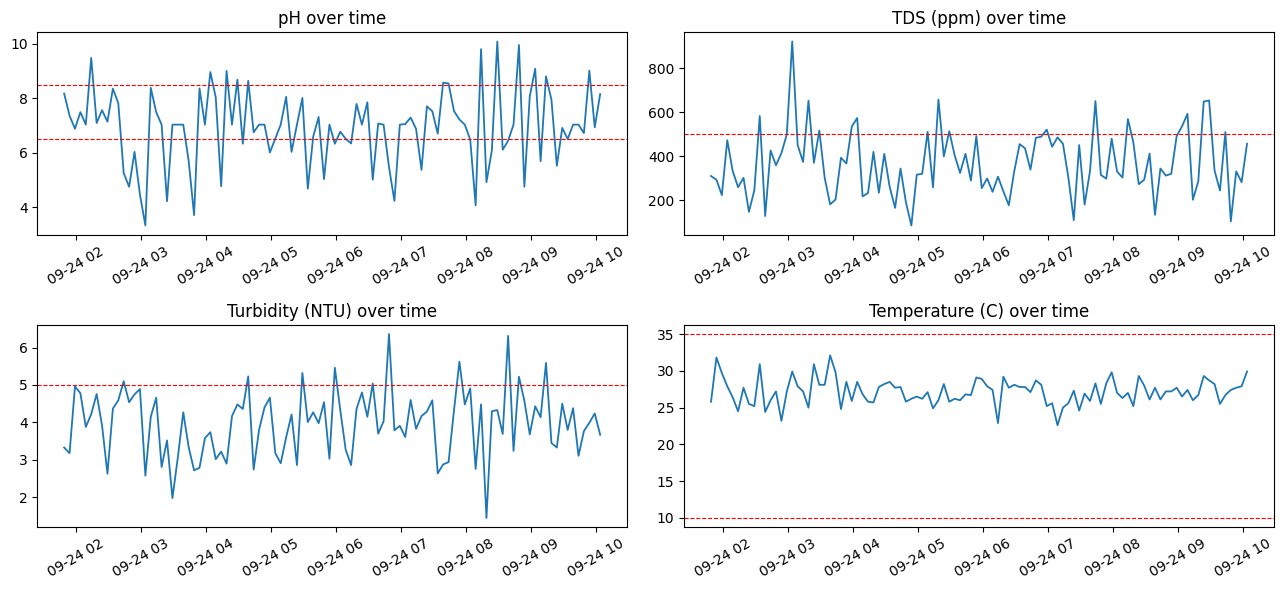

Recent alerts:


,ts,status,alert_msg
289,2026-09-24 09:14:00,UNSAFE,Abnormal Water Quality Detected: ph too high (...
291,2026-09-24 09:24:00,UNSAFE,Abnormal Water Quality Detected: ph too low (5...
292,2026-09-24 09:29:00,ATTENTION REQUIRED,Abnormal Water Quality Detected: tds too high ...
295,2026-09-24 09:44:00,ATTENTION REQUIRED,Abnormal Water Quality Detected: tds too high ...
297,2026-09-24 09:54:00,ATTENTION REQUIRED,Abnormal Water Quality Detected: ph too high (...


In [ ]:
COLORS = {"NORMAL": "#2e7d32", "ATTENTION REQUIRED": "#ef6c00", "UNSAFE": "#c62828"}
BOX = "padding:10px 16px;border:1px solid #ccc;border-radius:8px"

def dashboard(n=100):
    hist = pd.read_sql("SELECT * FROM readings ORDER BY id", conn, parse_dates=["ts"])
    last = hist.iloc[-1]
    color = COLORS[last["status"]]
    alert = f"<p style='color:{color};font-weight:bold'>&#9888; {last['alert_msg']}</p>" if last["alert_msg"] else ""

    display(HTML(f"""
    <div style="font-family:sans-serif">
      <h2 style="margin:0">Clean Drinking Water Monitoring Dashboard</h2>
      <p style="color:#666">Last reading: {last['ts']}</p>
      <div style="display:flex;gap:12px;flex-wrap:wrap">
        <div style="{BOX}">pH<br><b style="font-size:22px">{last['ph']}</b></div>
        <div style="{BOX}">TDS<br><b style="font-size:22px">{last['tds']:.0f} ppm</b></div>
        <div style="{BOX}">Turbidity<br><b style="font-size:22px">{last['turbidity']} NTU</b></div>
        <div style="{BOX}">Temperature<br><b style="font-size:22px">{last['temperature']} &deg;C</b></div>
        <div style="padding:10px 16px;border-radius:8px;background:{color};color:white">Status<br><b style="font-size:22px">{last['status']}</b></div>
      </div>
      {alert}
    </div>"""))

    recent = hist.tail(n)
    fig, axes = plt.subplots(2, 2, figsize=(13, 6))
    items = [("ph", "pH"), ("tds", "TDS (ppm)"), ("turbidity", "Turbidity (NTU)"), ("temperature", "Temperature (C)")]
    for ax, (col, label) in zip(axes.ravel(), items):
        ax.plot(recent["ts"], recent[col], lw=1.3)
        lo, hi = LIMITS[col]
        ax.axhline(hi, color="red", ls="--", lw=0.8)
        if lo > 0:
            ax.axhline(lo, color="red", ls="--", lw=0.8)
        ax.set_title(f"{label} over time")
        ax.tick_params(axis="x", rotation=30)
    plt.tight_layout()
    plt.show()

    print("Recent alerts:")
    display(hist[hist["status"] != "NORMAL"][["ts", "status", "alert_msg"]].tail(5))

dashboard()

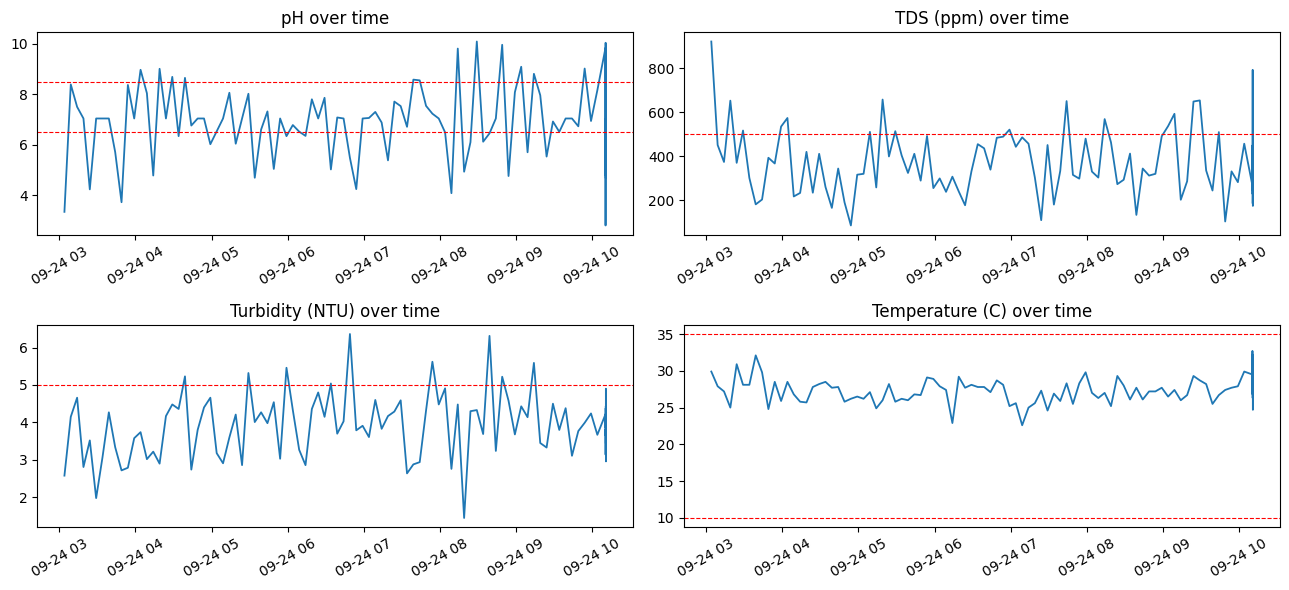

Recent alerts:


,ts,status,alert_msg
306,2026-09-24 10:10:37,ATTENTION REQUIRED,Abnormal Water Quality Detected: ph too low (6...
308,2026-09-24 10:10:40,UNSAFE,Abnormal Water Quality Detected: ph too low (4...
309,2026-09-24 10:10:42,ATTENTION REQUIRED,Abnormal Water Quality Detected: ph too low (5...
311,2026-09-24 10:10:45,ATTENTION REQUIRED,Abnormal Water Quality Detected: ph too low (6...
314,2026-09-24 10:10:51,ATTENTION REQUIRED,Abnormal Water Quality Detected: tds too high ...


In [ ]:
for i in range(N, N + 15):
    r = df.iloc[i][["ph", "tds", "turbidity", "temperature"]].to_dict()
    send_reading(r)
    clear_output(wait=True)
    dashboard()
    time.sleep(1)

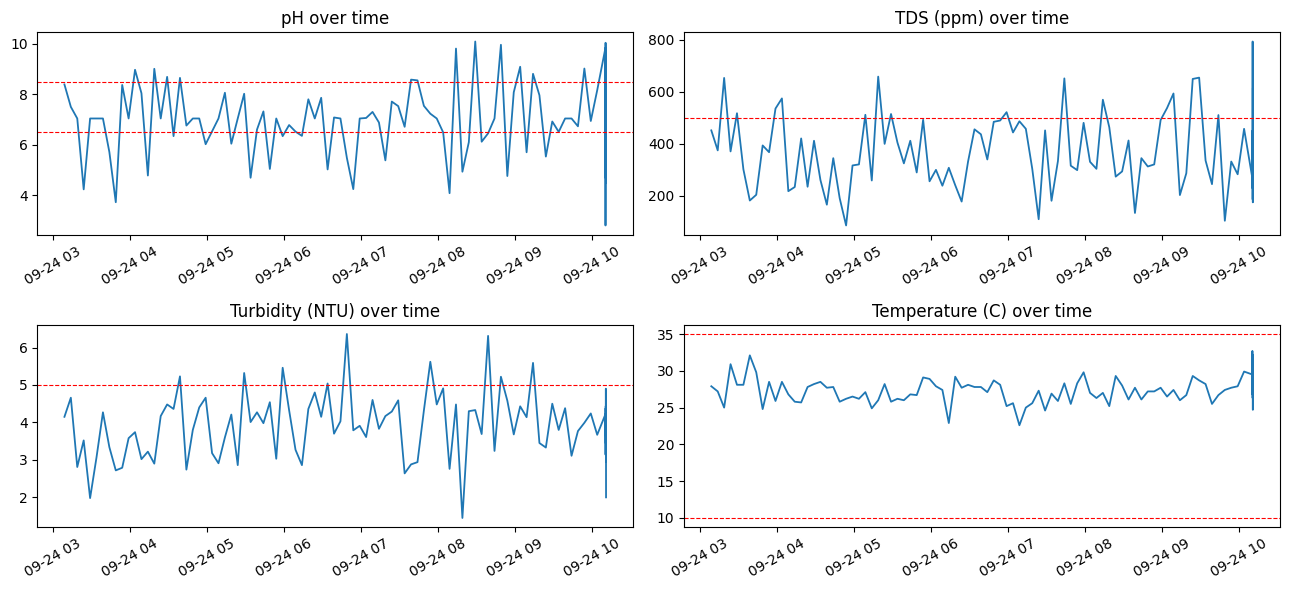

Recent alerts:


,ts,status,alert_msg
308,2026-09-24 10:10:40,UNSAFE,Abnormal Water Quality Detected: ph too low (4...
309,2026-09-24 10:10:42,ATTENTION REQUIRED,Abnormal Water Quality Detected: ph too low (5...
311,2026-09-24 10:10:45,ATTENTION REQUIRED,Abnormal Water Quality Detected: ph too low (6...
314,2026-09-24 10:10:51,ATTENTION REQUIRED,Abnormal Water Quality Detected: tds too high ...
315,2026-09-24 10:10:53,UNSAFE,Abnormal Water Quality Detected: ph too low (4.5)


In [ ]:
send_reading({"ph": 4.5, "tds": 350, "turbidity": 2, "temperature": 27})
clear_output(wait=True)
dashboard()

In [ ]:
out = pd.read_sql("SELECT * FROM readings ORDER BY id", conn)
out.to_csv("readings_export.csv", index=False)
print("Saved", len(out), "rows")

from google.colab import files
files.download("readings_export.csv")

Saved 316 rows


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>